In [2]:
import numpy as np
import matplotlib.pyplot as plt

import sim, plots
plt.rcParams["figure.figsize"] = (8, 4)
trapz = getattr(np, "trapezoid", None) or np.trapz       # depth integral

def dcm(res):
    """Depth and value of the phytoplankton maximum at every saved time."""
    k = res.P.argmax(axis=1)
    return res.depth[k], res.P[np.arange(len(k)), k]

### Operator-splitting accuracy

In [3]:
LIE      = [("growth", 1), ("sinking", 1), ("mixing", 1)]
STRANG   = [("growth", .5), ("sinking", .5), ("mixing", 1), ("sinking", .5), ("growth", .5)]
STRANG_B = [("mixing", .5), ("sinking", .5), ("growth", 1), ("sinking", .5), ("mixing", .5)]

def final_P(dt, splitting):
    return sim.run(DT_SECONDS=dt, T_END_DAYS=5, SAVE_EVERY_DAYS=5,
                   SPLITTING=splitting, SINKING_ENABLED=True).P[-1]

ref = final_P(11.25, STRANG)
dts = np.array([2*2*3600, 2*3600, 3600, 1800, 900, 450])
errors = {name: np.array([abs(final_P(dt, s) - ref).max() for dt in dts])
          for name, s in (("Lie", LIE), ("Strang (mixing in middle)", STRANG), ("Strang (growth in middle)", STRANG_B))}

for name, e in errors.items():
    print(f"{name:28s} errors {np.array2string(e, formatter={'float_kind': lambda x: f'{x:.2e}'})}   observed orders {np.round(np.log2(e[:-1] / e[1:]), 2)}")

Lie                          errors [2.54e-02 1.19e-02 5.94e-03 2.97e-03 1.48e-03 7.41e-04]   observed orders [1.09 1.   1.   1.   1.  ]
Strang (mixing in middle)    errors [2.73e-04 6.63e-05 1.65e-05 4.11e-06 1.03e-06 2.57e-07]   observed orders [2.04 2.01 2.   2.   2.  ]
Strang (growth in middle)    errors [3.95e-03 6.24e-04 1.54e-04 3.84e-05 9.60e-06 2.40e-06]   observed orders [2.66 2.02 2.   2.   2.  ]


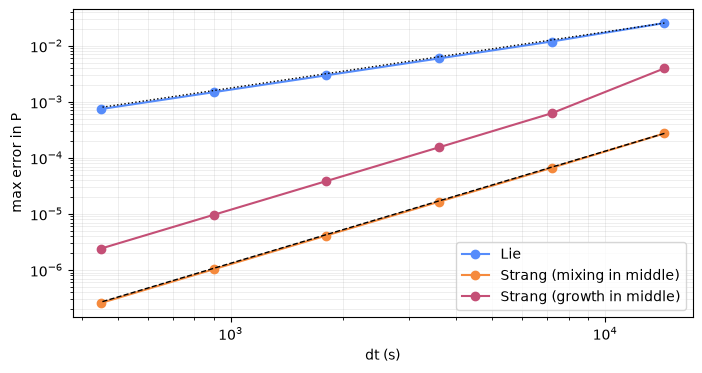

In [4]:
fig, ax = plt.subplots()
for name, e in errors.items():
    ax.loglog(dts, e, "o-", label=name)
ax.loglog(dts, errors["Lie"][0] * dts / dts[0], "k:", lw=1)
ax.loglog(dts, errors["Strang (mixing in middle)"][0] * (dts / dts[0]) ** 2, "k--", lw=1)
ax.set_xlabel("dt (s)"); ax.set_ylabel("max error in P"); ax.legend(); ax.grid(True, which="both", alpha=.3)
plt.show()

### $N_z$ comparison

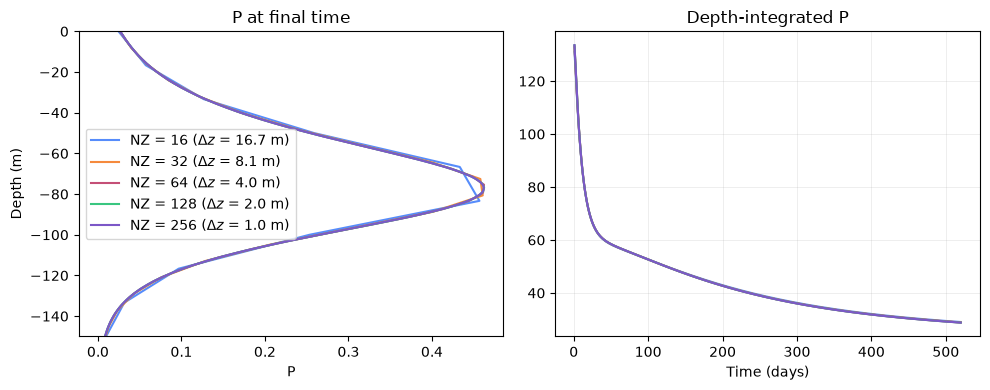

   NZ  dz (m)  max depth (m)   max P  max P err  total P err
   16   16.67          -83.3  0.4569      1.14%        0.80%
   32    8.06          -80.6  0.4608      0.28%        0.34%
   64    3.97          -75.4  0.4623      0.05%        0.14%
  128    1.97          -76.8  0.4625      0.09%        0.05%
  256    0.98          -77.5  0.4621      0.00%        0.00%


In [5]:
nz_list = (16, 32, 64, 128, 256)
nz_runs = {nz: sim.run(SINKING_ENABLED=True, SHADING_ENABLED=True, SHADING_MODE="integral", NZ=nz) for nz in nz_list}

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for nz, res in nz_runs.items():
    dz = res.depth[1] - res.depth[0]
    ax[0].plot(res.P[-1], res.depth, label=f"NZ = {nz} ($\\Delta z$ = {dz:.1f} m)")
    ax[1].plot(res.days, trapz(res.P, res.depth, axis=1), label=f"NZ = {nz}")
ax[0].set(title="P at final time", xlabel="P", ylabel="Depth (m)", ylim=(-150, 0)); ax[0].legend()
ax[1].set(title="Depth-integrated P", xlabel="Time (days)"); ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

ref = nz_runs[nz_list[-1]]
ref_peak, ref_tot = ref.P[-1].max(), trapz(ref.P[-1], ref.depth)
print(f"{'NZ':>5} {'dz (m)':>7} {'max depth (m)':>14} {'max P':>7} {'max P err':>10} {'total P err':>12}")
for nz, res in nz_runs.items():
    d, v = dcm(res)
    tot = trapz(res.P[-1], res.depth)
    print(f"{nz:>5} {res.depth[1] - res.depth[0]:>7.2f} {d[-1]:>14.1f} {v[-1]:>7.4f} "
          f"{abs(v[-1] - ref_peak) / ref_peak:>10.2%} {abs(tot - ref_tot) / ref_tot:>12.2%}")

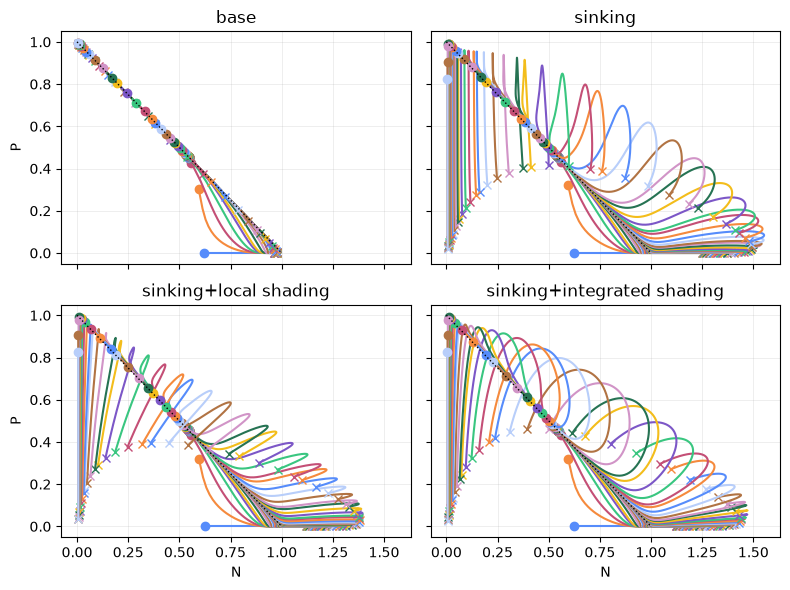

In [6]:
base = sim.run(SINKING_ENABLED=False, SHADING_ENABLED=False)
sink = sim.run(SINKING_ENABLED=True, SHADING_ENABLED=False)
shade_local = sim.run(SINKING_ENABLED=True, SHADING_ENABLED=True, SHADING_MODE="local")
shade_integral = sim.run(SINKING_ENABLED=True, SHADING_ENABLED=True, SHADING_MODE="integral")


phase_depths = np.linspace(-249, 1, 70)

fig, axs = plt.subplots(2, 2, figsize=(8, 6), sharex=True, sharey=True)
for a, (res, name) in zip(axs.flat, ((base, "base"), (sink, "sinking"),
                                     (shade_local, "sinking+local shading"), (shade_integral, "sinking+integrated shading"))):
    for d in phase_depths:
        k = np.argmin(abs(res.depth - d))
        line, = a.plot(res.N[:, k], res.P[:, k], label=f"{res.depth[k]:.0f} m")
        a.plot(res.N[0, k], res.P[0, k], "o", color=line.get_color())      # start
        a.plot(res.N[-1, k], res.P[-1, k], "x", color=line.get_color())    # end
    a.plot([0, 1], [1, 0], "k:", lw=1)                                     # N + P = 1
    a.set_title(name); a.grid(True, alpha=0.3)
for a in axs[1]: a.set_xlabel("N")
for a in axs[:, 0]: a.set_ylabel("P")
# axs[0, 0].legend()
plt.tight_layout()
plt.show()